 # LSTM Model Illustration Using the Airline Passengers Dataset

 In this example, a Long Short-Term Memory (LSTM) neural network is implemented to illustrate its application to time series forecasting. LSTM models are a class of recurrent neural networks specifically designed to capture temporal dependencies and nonlinear patterns in sequential data.

All packages used in the following code blocks must be installed prior to execution. These include `pandas`, `numpy`, `matplotlib`, `scikit-learn`, `statsmodels` and `keras`.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import mean_squared_error, mean_absolute_error
from keras.models import Sequential
from keras.layers import LSTM, Dense
from statsmodels.graphics.tsaplots import plot_acf, plot_pacf
from statsmodels.tsa.seasonal import seasonal_decompose

## Data Acquisition and Preprocessing

The dataset used is the well-known Airline Passengers dataset, which contains monthly totals of international airline passengers measured in thousands over time. The data is loaded directly from an online repository to ensure reproducibility.

In [2]:
# Load dataset directly from URL
url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/airline-passengers.csv"
df = pd.read_csv(url)

# Rename columns for convenience
df.columns = ["Month", "Passengers"]

# Convert Month to datetime
df["Month"] = pd.to_datetime(df["Month"])

# Set index
df.set_index("Month", inplace=True)

print(df.head())

            Passengers
Month                 
1949-01-01         112
1949-02-01         118
1949-03-01         132
1949-04-01         129
1949-05-01         121


## Visualization of the Time Series

Before modeling, it is important to visualize the data in order to identify patterns such as trend and seasonality.

In [3]:
# Pivot: rows = years, columns = months
# Create year and month columns
# Create year and month columns from index
df['Year'] = df.index.year
df['Month_num'] = df.index.month

# Check columns (debug step)
print(df.columns)

# Pivot table
table = df.pivot(index='Year', columns='Month_num', values='Passengers')

print(table)

df.drop(columns=['Year', 'Month_num'], inplace=True)


Index(['Passengers', 'Year', 'Month_num'], dtype='str')
Month_num   1    2    3    4    5    6    7    8    9    10   11   12
Year                                                                 
1949       112  118  132  129  121  135  148  148  136  119  104  118
1950       115  126  141  135  125  149  170  170  158  133  114  140
1951       145  150  178  163  172  178  199  199  184  162  146  166
1952       171  180  193  181  183  218  230  242  209  191  172  194
1953       196  196  236  235  229  243  264  272  237  211  180  201
1954       204  188  235  227  234  264  302  293  259  229  203  229
1955       242  233  267  269  270  315  364  347  312  274  237  278
1956       284  277  317  313  318  374  413  405  355  306  271  306
1957       315  301  356  348  355  422  465  467  404  347  305  336
1958       340  318  362  348  363  435  491  505  404  359  310  337
1959       360  342  406  396  420  472  548  559  463  407  362  405
1960       417  391  419  461  472

C:\Users\namel\AppData\Local\Temp\ipykernel_17516\717944306.py:6: UserWarning: No artists with labels found to put in legend.  Note that artists whose label start with an underscore are ignored when legend() is called with no argument.
  plt.legend()


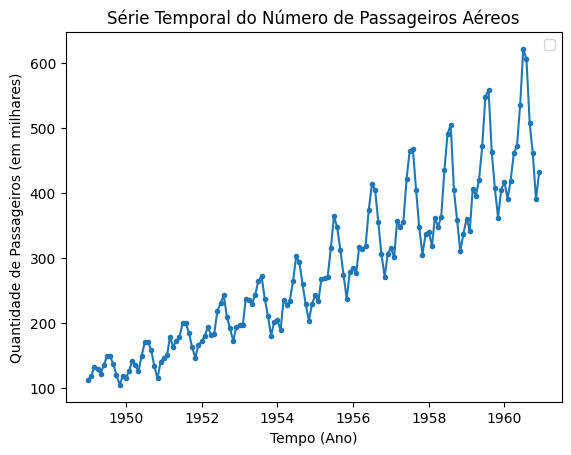

In [4]:
plt.plot(df, marker='o', markersize=3)
plt.title("Série Temporal do Número de Passageiros Aéreos")
plt.xlabel("Tempo (Ano)")
plt.ylabel("Quantidade de Passageiros (em milhares)")
plt.savefig("serie_temporal_passageiros_visualization_datos.png", dpi=300, bbox_inches='tight')
plt.legend()

<Figure size 640x480 with 0 Axes>

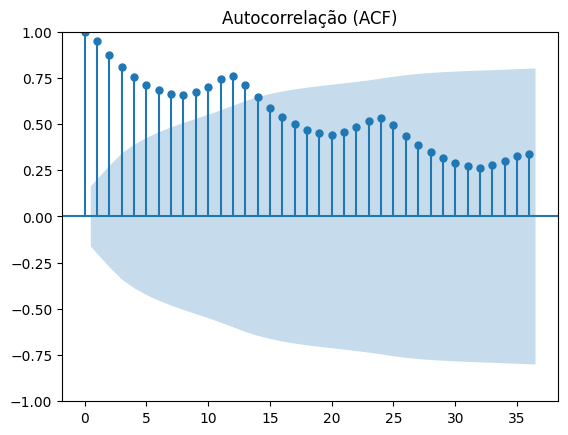

In [5]:
plt.figure()
plot_acf(df, lags=36)
plt.title("Autocorrelação (ACF)")
plt.savefig("serie_temporal_passageiros_ACF.png", dpi=300, bbox_inches='tight')
plt.show()

<Figure size 640x480 with 0 Axes>

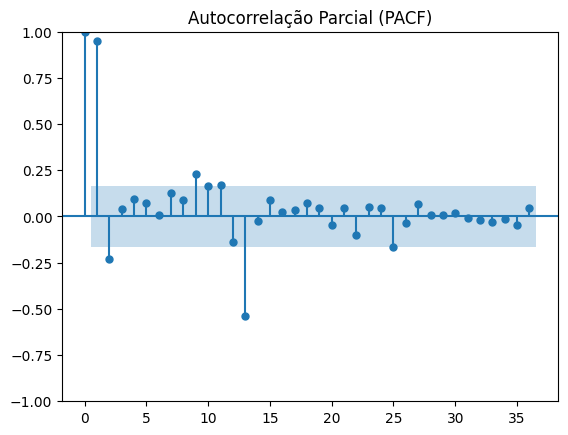

In [6]:
plt.figure()
plot_pacf(df, lags=36, method='ywm')
plt.title("Autocorrelação Parcial (PACF)")
plt.savefig("serie_temporal_passageiros_PACF.png", dpi=300, bbox_inches='tight')
plt.show()

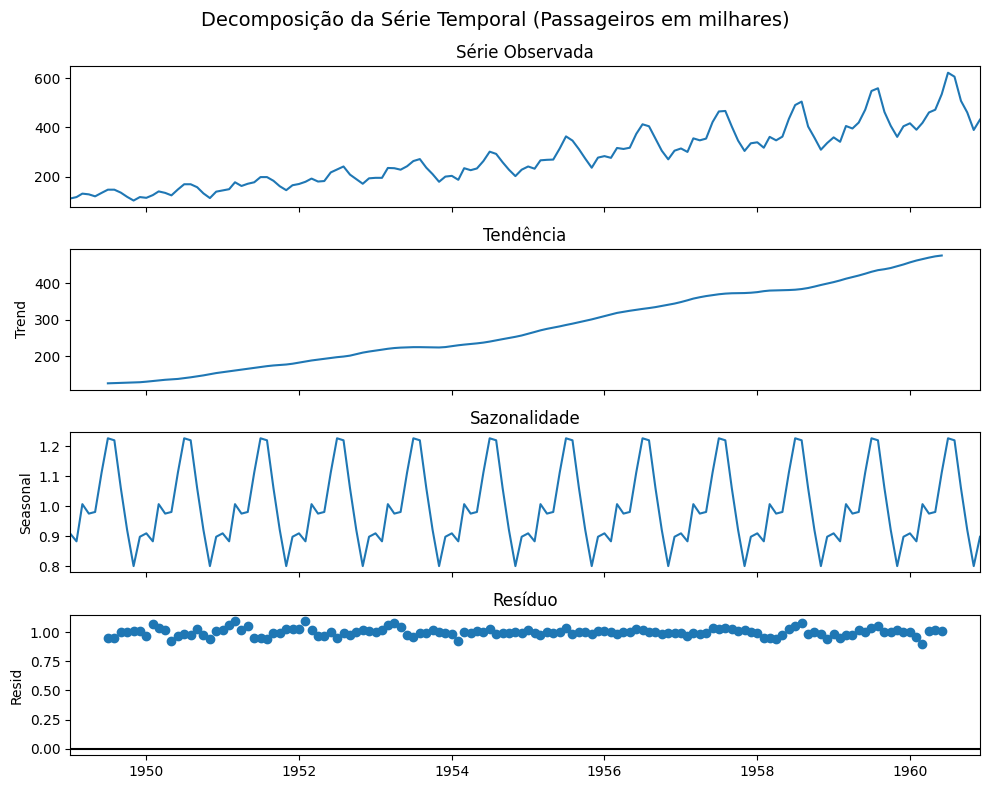

In [7]:
# Rename
series = df.copy()
series.name = "Número de Passageiros (em milhares)"

# Seasonal decomposition
decomposition = seasonal_decompose(series, model='multiplicative', period=12)

# Plot
fig = decomposition.plot()
fig.set_size_inches(10, 8)

# Adjust subplot titles
axes = fig.get_axes()

axes[0].set_title("Série Observada")
axes[1].set_title("Tendência")
axes[2].set_title("Sazonalidade")
axes[3].set_title("Resíduo")

# Overall title
plt.suptitle("Decomposição da Série Temporal (Passageiros em milhares)", fontsize=14)

plt.tight_layout()
plt.savefig("serie_temporal_passageiros_Decomposition.png", dpi=300, bbox_inches='tight')
plt.show()

In [8]:
print(np.shape(df))
print(df.index.min())
print(df.index.max())

(144, 1)
1949-01-01 00:00:00
1960-12-01 00:00:00


## Data Preparation for LSTM

LSTM models require the data to be normalized and structured into input-output sequences. A sliding window approach is used, where the previous 12 observations are used to predict the next value. To prevent data-leakage we first seperate the data into three sets.

### Seperate the data in test, train and validation datasets
A train/validation/test split is applied for methodological correctness, although limited data size affects statistical robustness.
70% of the data will be allocated for training, and 15% for testing and validation.

In [9]:
train_size = int(len(df) * 0.7)
val_size = int(len(df) * 0.15)

train = df.iloc[:train_size]
val = df.iloc[train_size:train_size + val_size]
test = df.iloc[train_size + val_size:]

### Normalizing Data & Generate data splits

In [10]:
# Normalize data
# Fit scaler ONLY on train to prevent data leakage
scaler = MinMaxScaler()
train_scaled = scaler.fit_transform(train.values)
val_scaled = scaler.transform(val.values)
test_scaled = scaler.transform(test.values)

# Create sequences
def create_dataset(data, time_step=1):
    X, y = [], []
    for i in range(len(data) - time_step):
        X.append(data[i:(i + time_step), 0])
        y.append(data[i + time_step, 0])
    return np.array(X), np.array(y)

time_step = 12  # one year window
X_train, y_train = create_dataset(train_scaled, time_step)
X_val, y_val = create_dataset(val_scaled, time_step)
X_test, y_test = create_dataset(test_scaled, time_step)

X_train = X_train.reshape(X_train.shape[0], X_train.shape[1], 1)
X_val   = X_val.reshape(X_val.shape[0], X_val.shape[1], 1)
X_test  = X_test.reshape(X_test.shape[0], X_test.shape[1], 1)

### Illustration of the different Datasets

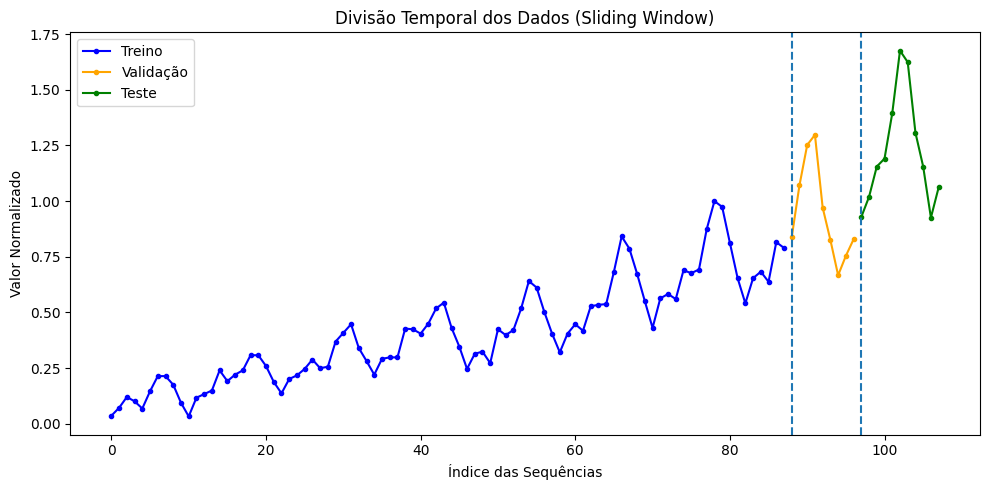

In [11]:
plt.figure(figsize=(10, 5))

# Define indices
train_idx = range(0, len(y_train))
val_idx = range(len(y_train), len(y_train) + len(y_val))
test_idx = range(len(y_train) + len(y_val),
                 len(y_train) + len(y_val) + len(y_test))

# Plot each split
plt.plot(train_idx, y_train, label="Treino", marker='o', markersize=3, color="blue")
plt.plot(val_idx, y_val, label="Validação", marker='o', markersize=3, color="orange")
plt.plot(test_idx, y_test, label="Teste", marker='o', markersize=3, color="green")

# Add vertical split lines (very useful visually)
plt.axvline(x=len(y_train), linestyle='--')
plt.axvline(x=len(y_train) + len(y_val), linestyle='--')

# Labels and title
plt.title("Divisão Temporal dos Dados (Sliding Window)")
plt.xlabel("Índice das Sequências")
plt.ylabel("Valor Normalizado")
plt.legend()

# Layout + save
plt.tight_layout()
plt.savefig("data_split_visualization.png", dpi=300, bbox_inches='tight')
plt.show()

## LSTM Model Construction and Training

An LSTM model is constructed using a single hidden layer followed by a dense output layer. The model is trained using the Adam optimizer and mean squared error loss function.

In [12]:
# Build model
model = Sequential()
model.add(LSTM(50, return_sequences=False, input_shape=(time_step, 1)))
model.add(Dense(1))
model.summary()

model.compile(optimizer='adam', loss='mean_squared_error')

# Sanity Check
print("X_train:", X_train.shape)
print("X_val:", X_val.shape)
print("X_test:", X_test.shape)
print("Model input:", model.input_shape)


C:\01b_TUM\26_SoSe_MA4\TimeSeries\.venv\Lib\site-packages\keras\src\layers\rnn\rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 50)             │        10,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            51 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,451 (40.82 KB)

 Trainable params: 10,451 (40.82 KB)

 Non-trainable params: 0 (0.00 B)

X_train: (88, 12, 1)
X_val: (9, 12, 1)
X_test: (11, 12, 1)
Model input: (None, 12, 1)


In [13]:
# Train model
history = model.fit(
    X_train, y_train,
    epochs=50,
    batch_size=8,
    validation_data=(X_val, y_val),
    verbose=1
)

Epoch 1/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 7s 69ms/step - loss: 0.1317 - val_loss: 0.2392
Epoch 2/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 19ms/step - loss: 0.0287 - val_loss: 0.0586
Epoch 3/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 16ms/step - loss: 0.0187 - val_loss: 0.0844
Epoch 4/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 20ms/step - loss: 0.0163 - val_loss: 0.0741
Epoch 5/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0143 - val_loss: 0.0573
Epoch 6/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step - loss: 0.0133 - val_loss: 0.0595
Epoch 7/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 13ms/step - loss: 0.0134 - val_loss: 0.0585
Epoch 8/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0133 - val_loss: 0.0541
Epoch 9/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 12ms/step - loss: 0.0124 - val_loss: 0.0557
Epoch 10/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0126 - val_loss: 0.0536
Epoch 11/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 10ms/step - loss: 0.0120 - val_loss: 0.0532
Epoch 12/50
11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 11ms/step - loss: 0.0

### Plot Training vs Validation Loss to Account for Overfitting

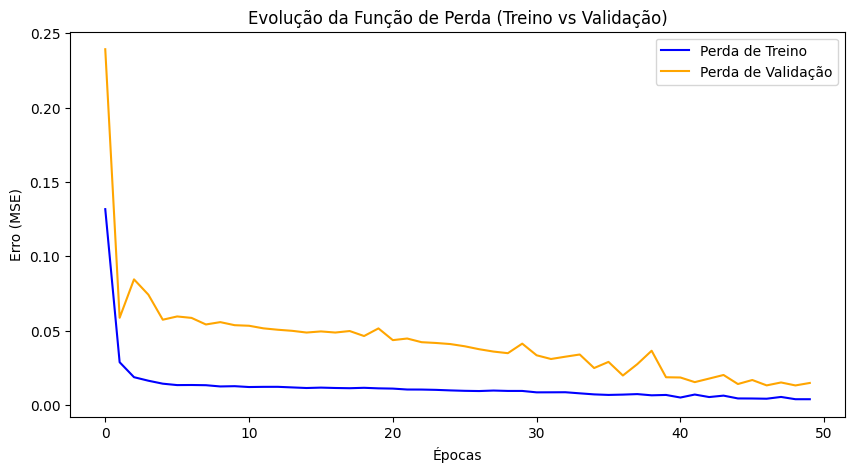

In [14]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10,5))
plt.plot(history.history['loss'], label="Perda de Treino", color="blue")
plt.plot(history.history['val_loss'], label="Perda de Validação", color="orange")

plt.title("Evolução da Função de Perda (Treino vs Validação)")
plt.xlabel("Épocas")
plt.ylabel("Erro (MSE)")
plt.legend()
plt.savefig("serie_temporal_passageiros_trainingProcess.png", dpi=300, bbox_inches='tight')
plt.show()

## Prediction and Results

After training, the model is used to generate predictions, which are then transformed back to the original scale for interpretation.

#### Predict one step ahead

In [15]:
print(X_train[1].reshape(1, -1, 1))
model.predict(X_train[1].reshape(1, -1, 1))

[[[0.04530744]
  [0.09061489]
  [0.08090615]
  [0.05501618]
  [0.10032362]
  [0.14239482]
  [0.14239482]
  [0.10355987]
  [0.04854369]
  [0.        ]
  [0.04530744]
  [0.03559871]]]
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 265ms/step


array([[0.12085151]], dtype=float32)

In [16]:
# Predictions
y_pred_train = model.predict(X_train)
y_pred_val = model.predict(X_val)
y_pred_test = model.predict(X_test)

# Reshape true values (required for inverse_transform)
y_train_2d = y_train.reshape(-1, 1)
y_val_2d = y_val.reshape(-1, 1)
y_test_2d = y_test.reshape(-1, 1)

# Inverse transform predictions
y_pred_train_inv = scaler.inverse_transform(y_pred_train)
y_pred_val_inv = scaler.inverse_transform(y_pred_val)
y_pred_test_inv = scaler.inverse_transform(y_pred_test)

# Inverse transform true values
y_train_inv = scaler.inverse_transform(y_train_2d)
y_val_inv = scaler.inverse_transform(y_val_2d)
y_test_inv = scaler.inverse_transform(y_test_2d)

3/3 ━━━━━━━━━━━━━━━━━━━━ 0s 14ms/step 
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 61ms/step


#### Predict various steps ahead

In [17]:
import numpy as np

def recursive_forecast(model, last_window, n_steps):
    """
    model: trained LSTM model
    last_window: array with the last known values (shape: time_step,)
    n_steps: number of future time steps to predict
    """

    # list to store all predicted values
    predictions = []

    # make a copy so we don't modify the original data
    current_window = last_window.copy()

    # loop to predict one step at a time
    for _ in range(n_steps):

        x_input = current_window.reshape(1, -1, 1)

        # predict the next value
        y_pred = model.predict(x_input, verbose=0)

        # extract the predicted scalar value
        next_value = y_pred

        # store prediction in list
        predictions.append(next_value)

        # update the window:
        # remove the first (oldest) value
        # append the new predicted value at the end
        current_window = np.append(current_window[1:], next_value)

    # return all predictions as a numpy array
    return np.array(predictions)

In [18]:
# make forecast for test_data
# predict as many steps as your test set length
y_pred_test_recursive = recursive_forecast(model, X_test[0], len(y_test))
y_pred_test_recursive_inv = scaler.inverse_transform(y_pred_test_recursive.reshape(-1, 1))

## Visualization of Predictions

### Only for Test-Dataset
The predicted values are compared with the actual observations of the unknown test dataset to evaluate the model's performance visually.

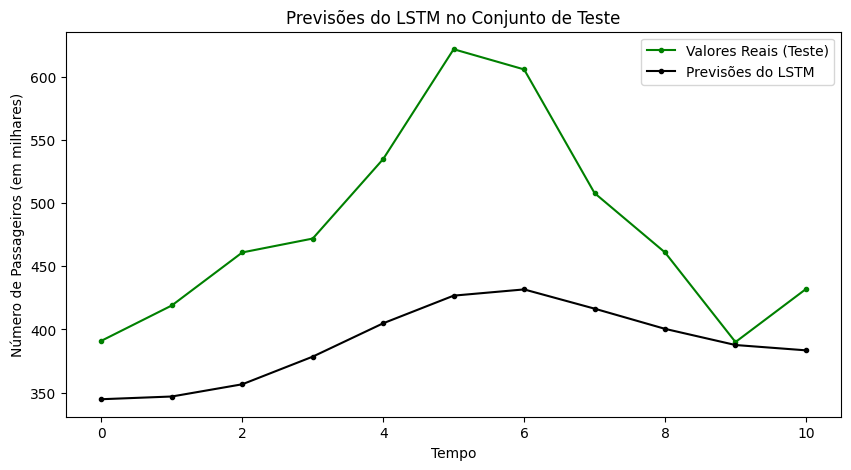

In [19]:
plt.figure(figsize=(10,5))

plt.plot(y_test_inv, marker='o', markersize=3, label="Valores Reais (Teste)", color="green")
plt.plot(y_pred_test_recursive_inv, marker='o', markersize=3, label="Previsões do LSTM", color="black")

plt.title("Previsões do LSTM no Conjunto de Teste")
plt.xlabel("Tempo")
plt.ylabel("Número de Passageiros (em milhares)")
plt.legend()
plt.savefig("serie_temporal_passageiros_previsionTestData.png", dpi=300, bbox_inches='tight')
plt.show()

In [20]:
rmse = np.sqrt(mean_squared_error(y_test_inv, y_pred_test_inv))
mae = mean_absolute_error(y_test_inv, y_pred_test_inv)

print("RMSE:", rmse)
print("MAE:", mae)

RMSE: 86.82747924151053
MAE: 78.05585549094461


### for Complete Dataset - One step ahead predicition

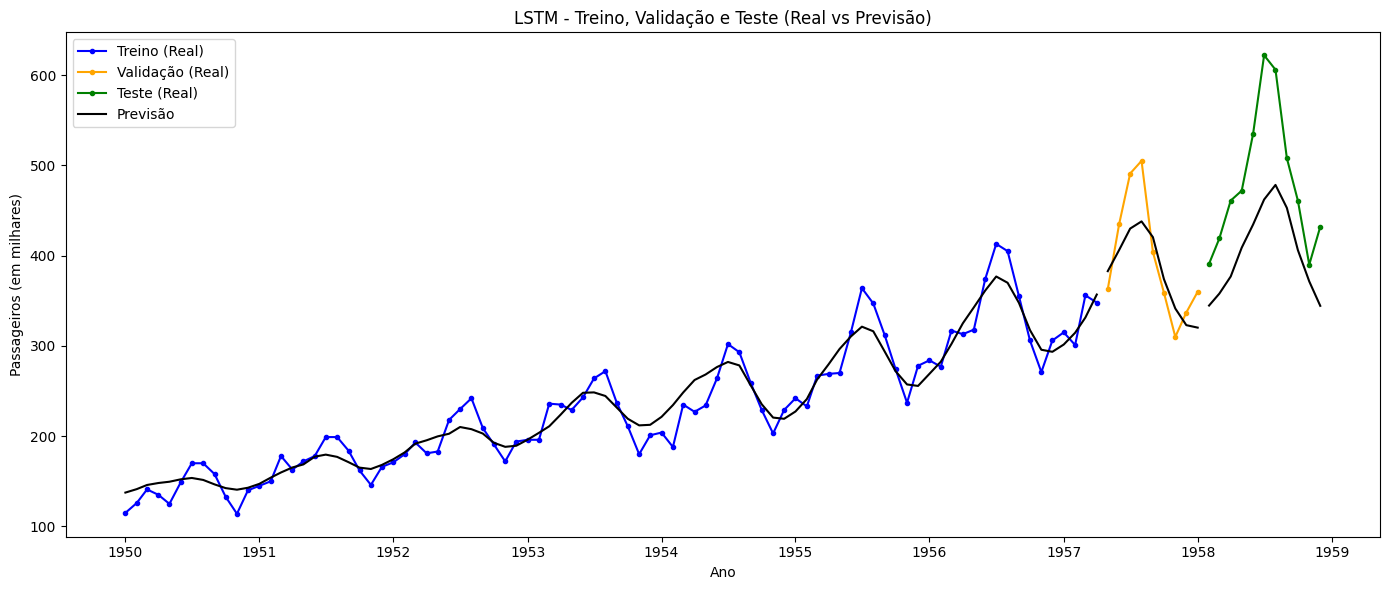

In [27]:
import numpy as np
import matplotlib.pyplot as plt



# SPLIT BOUNDARIES

# base time axis (already shifted by sliding window)
time_step = 12
t = df.index[time_step:]

# use TRUE lengths from windowed datasets
t_train = t[:len(y_train_inv)]
t_val   = t[len(y_train_inv):len(y_train_inv) + len(y_val_inv)]
t_test  = t[len(y_train_inv) + len(y_val_inv):len(y_train_inv) + len(y_val_inv) + len(y_test_inv)]


# REAL VALUES

y_train_plot = y_train_inv.reshape(-1)
y_val_plot   = y_val_inv.reshape(-1)
y_test_plot  = y_test_inv.reshape(-1)


# PREDICTIONS
y_pred_train_plot = y_pred_train_inv.reshape(-1)
y_pred_val_plot   = y_pred_val_inv.reshape(-1)
y_pred_test_plot  = y_pred_test_inv.reshape(-1)


# PLOT
plt.figure(figsize=(14,6))

# ---- TRAIN ----
plt.plot(t_train, y_train_plot,
         label="Treino (Real)", color="blue", marker='o', markersize=3)

plt.plot(t_train, y_pred_train_plot,
         color="black", markersize=3)

# ---- VALIDATION ----
plt.plot(t_val, y_val_plot,
         label="Validação (Real)", color="orange", marker='o', markersize=3)

plt.plot(t_val, y_pred_val_plot,
          color="black", markersize=3)

# ---- TEST ----
plt.plot(t_test, y_test_plot,
         label="Teste (Real)", color="green", marker='o', markersize=3)

plt.plot(t_test, y_pred_test_plot,
         label="Previsão", color="black", markersize=3)


# FORMATTING
plt.title("LSTM - Treino, Validação e Teste (Real vs Previsão)")
plt.xlabel("Ano")
plt.ylabel("Passageiros (em milhares)")
plt.legend()

plt.tight_layout()
plt.savefig("serie_temporal_passageiros_previsionAlldata.png",
            dpi=300,
            bbox_inches='tight')

plt.show()